In [1]:
import os
import re
import json
import time
import math
from collections import Counter, defaultdict
from pathlib import Path
from typing import Generator, Any, Optional

import pandas as pd
import numpy as np

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, *args, **kwargs):
        return iterable

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    plt.rcParams["figure.dpi"] = 120
    plt.rcParams["font.sans-serif"] = "DejaVu Sans"
    HAS_PLT = True
except ImportError:
    HAS_PLT = False

from IPython.display import HTML, display

# Configuracoes de exibicao do pandas
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

print("[OK] Bibliotecas carregadas com sucesso.")


[OK] Bibliotecas carregadas com sucesso.


In [3]:
#@title Parametros Globais de Analise
# 1. Pasta onde estao os arquivos de pares gerados (pares_*.jsonl)
PASTA_PARES = "/content/drive/MyDrive/Pares_Tribunais" #@param {type:"string"}

# 2. Padrao dos arquivos a serem analisados
PADRAO_ARQUIVOS = "pares_*.jsonl" #@param {type:"string"}

# 3. Amostragem por tribunal (0 = analisa 100% de todos os registros; >0 para analise rapida de teste)
AMOSTRAGEM_POR_TRIBUNAL = 0 #@param {type:"integer"}

caminho_base = Path(PASTA_PARES)
assert caminho_base.exists(), f"[ERRO] Diretorio nao encontrado: {caminho_base}"

print("=" * 84)
print(f"Diretorio de Pares : {caminho_base}")
print(f"Padrao de Busca    : {PADRAO_ARQUIVOS}")
print(f"Modo de Analise    : {'Completo (100% dos registros)' if AMOSTRAGEM_POR_TRIBUNAL <= 0 else f'Amostragem ({AMOSTRAGEM_POR_TRIBUNAL} reg/tribunal)'}")
print("=" * 84)


Diretorio de Pares : /content/drive/MyDrive/Pares_Tribunais
Padrao de Busca    : pares_*.jsonl
Modo de Analise    : Completo (100% dos registros)


## 2. Inventario e Mapeamento dos Arquivos
Varre o diretorio, identifica as siglas dos tribunais e calcula o tamanho de cada arquivo em disco.

In [4]:
# Varredura dos arquivos correspondentes
arquivos_encontrados = sorted(list(caminho_base.glob(PADRAO_ARQUIVOS)), key=lambda p: p.stat().st_size, reverse=True)

# Ignora eventuais amostras temporarias ou backups se existirem
lista_arquivos = []
for arq in arquivos_encontrados:
    nome = arq.name.lower()
    if "amostra" in nome or "temp" in nome or "backup" in nome:
        continue
    lista_arquivos.append(arq)

assert len(lista_arquivos) > 0, f"[ERRO] Nenhum arquivo correspondente a '{PADRAO_ARQUIVOS}' encontrado em: {caminho_base}"

linhas_inventario = []
total_bytes_geral = 0

for arq in lista_arquivos:
    tam_bytes = arq.stat().st_size
    total_bytes_geral += tam_bytes

    # Extrai a sigla a partir do nome: pares_sigla.jsonl ou pares_sigla_verificado.jsonl
    partes = arq.stem.replace("pares_", "").split("_")
    sigla_estimada = partes[0].upper()

    mtime = time.strftime("%Y-%m-%d %H:%M", time.localtime(arq.stat().st_mtime))

    linhas_inventario.append({
        "Tribunal": sigla_estimada,
        "Arquivo": arq.name,
        "Tamanho (MB)": round(tam_bytes / 1e6, 1),
        "Tamanho (GB)": round(tam_bytes / 1e9, 2),
        "Ultima Modificacao": mtime,
        "Caminho": arq
    })

df_inventario = pd.DataFrame(linhas_inventario)

print("=" * 84)
print("INVENTARIO DE ARQUIVOS CONCLUIDO:")
print(f"  - Total de Arquivos Encontrados: {len(df_inventario)}")
print(f"  - Tamanho Total em Disco       : {total_bytes_geral / 1e9:.2f} GB ({total_bytes_geral / 1e6:.1f} MB)")
print("=" * 84)
display(df_inventario[["Tribunal", "Arquivo", "Tamanho (MB)", "Tamanho (GB)", "Ultima Modificacao"]])


INVENTARIO DE ARQUIVOS CONCLUIDO:
  - Total de Arquivos Encontrados: 18
  - Tamanho Total em Disco       : 60.17 GB (60172.1 MB)


,Tribunal,Arquivo,Tamanho (MB),Tamanho (GB),Ultima Modificacao
0,TST,pares_tst.jsonl,14375.20,14.38,2026-09-23 13:30
1,TJRS,pares_tjrs.jsonl,10849.30,10.85,2026-09-23 04:57
2,TJDF,pares_tjdf.jsonl,6748.70,6.75,2026-09-23 04:16
3,TJPB,pares_tjpb.jsonl,5150.40,5.15,2026-09-23 03:35
4,TJBA,pares_tjba.jsonl,4089.30,4.09,2026-09-23 05:15
5,STF,pares_stf.jsonl,4066.60,4.07,2026-09-23 12:15
6,TJES,pares_tjes.jsonl,2881.30,2.88,2026-09-23 12:46
7,TJMS,pares_tjms.jsonl,2618.80,2.62,2026-09-22 22:41
8,TJPR,pares_tjpr.jsonl,2612.90,2.61,2026-09-24 02:52
9,TJPA,pares_tjpa.jsonl,2212.10,2.21,2026-09-23 12:58


## 3. Extracao de Metricas Textuais em Streaming
Leitura em fluxo continuo linha a linha sem carregar arquivos inteiros na memoria RAM. Coleta contagens exatas de palavras, caracteres, integridade de schema e duplicatas.


In [9]:
def iterar_pares(caminho: Path, limite: Optional[int] = None) -> Generator[dict[str, Any], None, None]:
    """Leitura linha a linha sem carregar o arquivo na memoria RAM."""
    count = 0
    with open(caminho, "r", encoding="utf-8", errors="replace") as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            try:
                rec = json.loads(linha)
                if isinstance(rec, dict):
                    yield rec
                    count += 1
                    if limite and count >= limite:
                        return
            except Exception:
                continue

# Estruturas para agregacao
metricas_tribunais = {}
todas_ementas_words = {}
todos_teores_words = {}
todas_razoes = {}
registros_amostra_visual = {}

global_ids_vistos = set()
duplicatas_cruzadas_total = 0
total_pares_global = 0

print("Iniciando auditoria textual em streaming...")
pbar_global = tqdm(df_inventario.iterrows(), total=len(df_inventario), desc="Auditando Arquivos", unit=" arq")

for _, item in pbar_global:
    arq_path = item["Caminho"]
    sigla_doc = item["Tribunal"]

    n_lidos = 0
    n_validos = 0
    n_duplicados_internos = 0
    vistos_tribunal = set()

    lista_p_eme = []
    lista_p_teo = []
    lista_c_eme = []
    lista_c_teo = []
    lista_razao = []

    amostra_visual = []
    limite_leitura = None if AMOSTRAGEM_POR_TRIBUNAL <= 0 else AMOSTRAGEM_POR_TRIBUNAL

    for rec in iterar_pares(arq_path, limite=limite_leitura):
        n_lidos += 1

        sigla_rec = str(rec.get("str_tribunal") or sigla_doc).upper().strip()
        num_unico = str(rec.get("str_numero_unico", "")).strip()
        eme = str(rec.get("str_ementa", "")).strip()
        teo = str(rec.get("str_inteiro_teor", "")).strip()

        # Deteccao de duplicata interna por numero unico
        chave_norm = re.sub(r"[^\w]+", "", num_unico)
        if chave_norm:
            if chave_norm in vistos_tribunal:
                n_duplicados_internos += 1
            else:
                vistos_tribunal.add(chave_norm)

            # Deteccao de duplicata cruzada entre diferentes arquivos
            id_global = f"{sigla_rec}_{chave_norm}"
            if id_global in global_ids_vistos:
                duplicatas_cruzadas_total += 1
            else:
                global_ids_vistos.add(id_global)

        p_eme = len(eme.split())
        p_teo = len(teo.split())
        c_eme = len(eme)
        c_teo = len(teo)

        if p_eme > 0 and p_teo > 0:
            n_validos += 1
            lista_p_eme.append(p_eme)
            lista_p_teo.append(p_teo)
            lista_c_eme.append(c_eme)
            lista_c_teo.append(c_teo)
            razao = round(p_teo / max(p_eme, 1), 2)
            lista_razao.append(razao)

            # Amostra para visualizador qualitativo
            if len(amostra_visual) < 3 and p_eme >= 40:
                amostra_visual.append({
                    "numero": num_unico,
                    "palavras_ementa": p_eme,
                    "palavras_teor": p_teo,
                    "razao": razao,
                    "ementa": eme[:280] + ("..." if len(eme) > 280 else ""),
                    "teor": teo[:320] + ("..." if len(teo) > 320 else "")
                })

    total_pares_global += n_validos

    # Calculo das estatisticas consolidadas
    if lista_p_eme:
        arr_p_eme = np.array(lista_p_eme)
        arr_p_teo = np.array(lista_p_teo)
        arr_razao = np.array(lista_razao)

        metricas_tribunais[sigla_doc] = {
            "Tribunal": sigla_doc,
            "Arquivo": item["Arquivo"],
            "Tamanho_MB": item["Tamanho (MB)"],
            "Total_Lidos": n_lidos,
            "Pares_Validos": n_validos,
            "Duplicados_Internos": n_duplicados_internos,
            "Taxa_Duplicatas": (n_duplicados_internos / max(1, n_lidos)) * 100,

            # Estatisticas Ementa (Palavras)
            "Ementa_Min": int(np.min(arr_p_eme)),
            "Ementa_Media": round(arr_p_eme.mean(), 1),
            "Ementa_Mediana": int(np.median(arr_p_eme)),
            "Ementa_Max": int(np.max(arr_p_eme)),

            # Estatisticas Teor (Palavras)
            "Teor_Min": int(np.min(arr_p_teo)),
            "Teor_Media": round(arr_p_teo.mean(), 1),
            "Teor_Mediana": int(np.median(arr_p_teo)),
            "Teor_Max": int(np.max(arr_p_teo)),

            # Razao
            "Razao_Mediana": round(float(np.median(arr_razao)), 2),
        }

        # Subamostragem uniforme para graficos boxplot/scatter (mantem RAM e renderizacao leves)
        passo = max(1, len(lista_p_eme) // 2500)
        todas_ementas_words[sigla_doc] = lista_p_eme[::passo]
        todos_teores_words[sigla_doc] = lista_p_teo[::passo]
        todas_razoes[sigla_doc] = lista_razao[::passo]
        registros_amostra_visual[sigla_doc] = amostra_visual

print(f"\n[OK] Auditoria textual concluida. Total de pares validos analisados: {total_pares_global:,}")

Iniciando auditoria textual em streaming...


Auditando Arquivos:   0%|          | 0/18 [00:00<?, ? arq/s]


[OK] Auditoria textual concluida. Total de pares validos analisados: 2,937,474


## 4. Tabela Mestra Consolidada


In [10]:
if metricas_tribunais:
    df_resumo = pd.DataFrame(list(metricas_tribunais.values()))

    # Ordena pelo volume de pares decrescente
    df_resumo = df_resumo.sort_values("Pares_Validos", ascending=False).reset_index(drop=True)

    # Calcula percentual do total geral
    df_resumo["% do Total"] = (df_resumo["Pares_Validos"] / df_resumo["Pares_Validos"].sum()) * 100

    # Tabela formatada para apresentacao em tela
    df_display = pd.DataFrame({
        "Tribunal": df_resumo["Tribunal"],
        "Pares Validos": df_resumo["Pares_Validos"].map(lambda x: f"{x:,}"),
        "% do Total": df_resumo["% do Total"].map(lambda x: f"{x:.1f}%"),
        "Disco (MB)": df_resumo["Tamanho_MB"].map(lambda x: f"{x:.1f}"),
        "Ementa mediana": df_resumo["Ementa_Mediana"],
        "Teor mediana": df_resumo["Teor_Mediana"],
        "Razao Teor/Em mediana": df_resumo["Razao_Mediana"].map(lambda x: f"{x:.1f}x"),
        "Duplicatas (%)": df_resumo["Taxa_Duplicatas"].map(lambda x: f"{x:.1f}%"),
    })

    # Calculo de totais e medias gerais
    tot_pares = df_resumo["Pares_Validos"].sum()
    tot_mb = df_resumo["Tamanho_MB"].sum()
    media_eme = df_resumo["Ementa_Mediana"].mean()
    media_teo = df_resumo["Teor_Mediana"].mean()
    mediana_razao = df_resumo["Razao_Mediana"].median()

    print("=" * 110)
    print("RESUMO EXECUTIVO DO DATASET GLOBAL DE PARES:")
    print(f"  - Total de Tribunais / Arquivos   : {len(df_resumo)}")
    print(f"  - Total de Pares Validos          : {tot_pares:,}")
    print(f"  - Volume Total em Disco           : {tot_mb / 1024:.2f} GB ({tot_mb:.1f} MB)")
    print(f"  - Mediana Geral Ementa (palavras) : {int(media_eme)} palavras")
    print(f"  - Mediana Geral Teor (palavras)   : {int(media_teo)} palavras")
    print(f"  - Razao Mediana Teor / Ementa     : {mediana_razao:.1f}x")
    print("=" * 110)
    display(df_display)
else:
    print("Nenhum dado encontrado para gerar o resumo.")

RESUMO EXECUTIVO DO DATASET GLOBAL DE PARES:
  - Total de Tribunais / Arquivos   : 18
  - Total de Pares Validos          : 2,937,474
  - Volume Total em Disco           : 58.76 GB (60172.1 MB)
  - Mediana Geral Ementa (palavras) : 234 palavras
  - Mediana Geral Teor (palavras)   : 2433 palavras
  - Razao Mediana Teor / Ementa     : 10.6x


,Tribunal,Pares Validos,% do Total,Disco (MB),Ementa mediana,Teor mediana,Razao Teor/Em mediana,Duplicatas (%)
0,TJBA,"497,163",16.9%,4089.3,82,908,11.2x,0.0%
1,TST,"486,135",16.5%,14375.2,225,3031,12.0x,0.0%
2,TJRS,"482,492",16.4%,10849.3,190,2465,13.2x,0.0%
3,TJPB,"298,494",10.2%,5150.4,283,1844,6.3x,0.0%
4,TJDF,"278,234",9.5%,6748.7,278,2620,10.1x,0.0%
5,TJPR,"199,827",6.8%,2612.9,114,1333,11.0x,0.0%
6,TJES,"151,826",5.2%,2881.3,340,1904,6.2x,0.0%
7,TJMS,"126,778",4.3%,2618.8,191,2093,10.2x,0.0%
8,TJPA,"107,317",3.7%,2212.1,431,2215,5.5x,0.0%
9,STF,"80,813",2.8%,4066.6,154,4191,27.6x,0.0%


## 5. Visualização de Dados (Gráficos)
Análise visual do volume de dados e da distribuição de palavras nos textos.

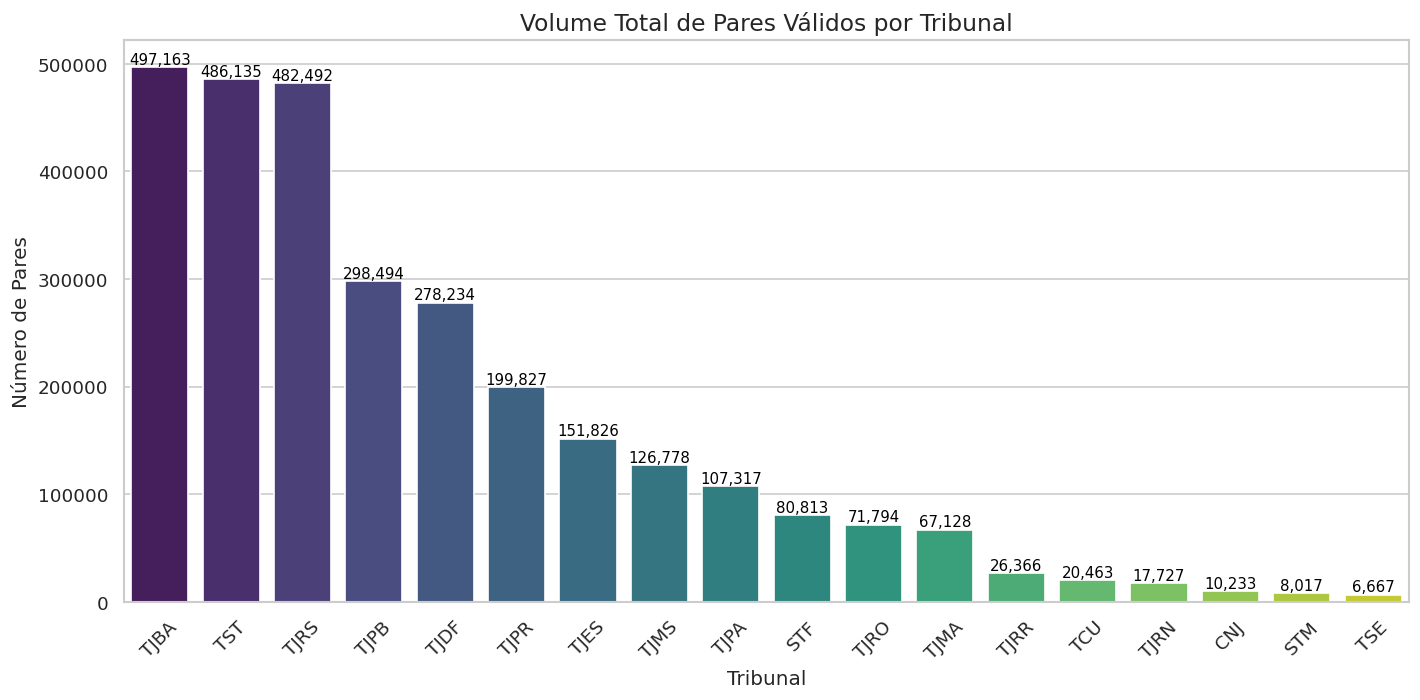

In [14]:
# Gráfico 1: Volume de Pares Válidos por Tribunal
plt.figure(figsize=(12, 6))
sns.barplot(data=df_resumo, x='Tribunal', y='Pares_Validos', hue='Tribunal', palette='viridis', legend=False)
plt.title('Volume Total de Pares Válidos por Tribunal', fontsize=14)
plt.xlabel('Tribunal', fontsize=12)
plt.ylabel('Número de Pares', fontsize=12)

# Adiciona os valores no topo de cada barra
for index, row in df_resumo.iterrows():
    plt.text(index, row.Pares_Validos, f'{int(row.Pares_Validos):,}', color='black', ha='center', va='bottom', fontsize=9)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

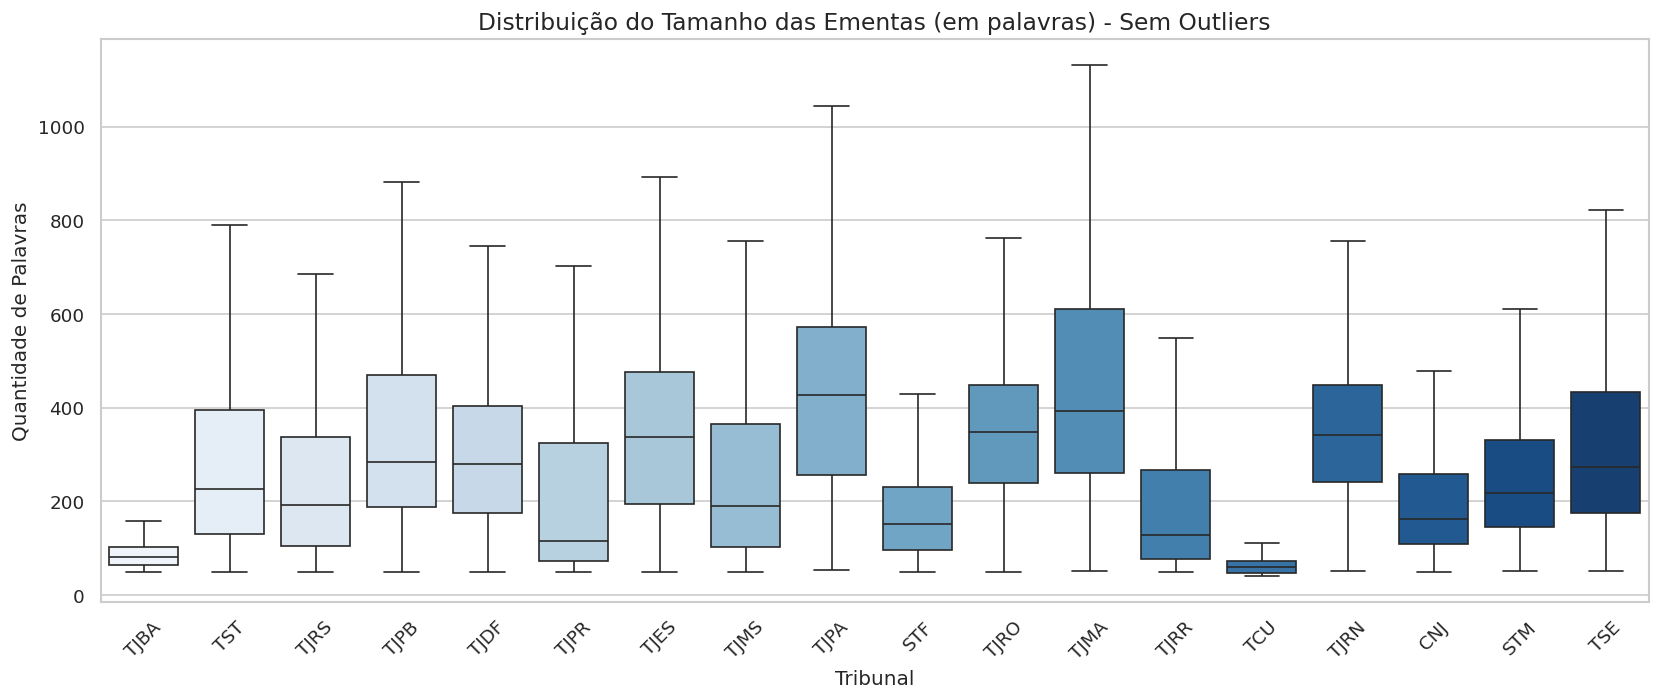

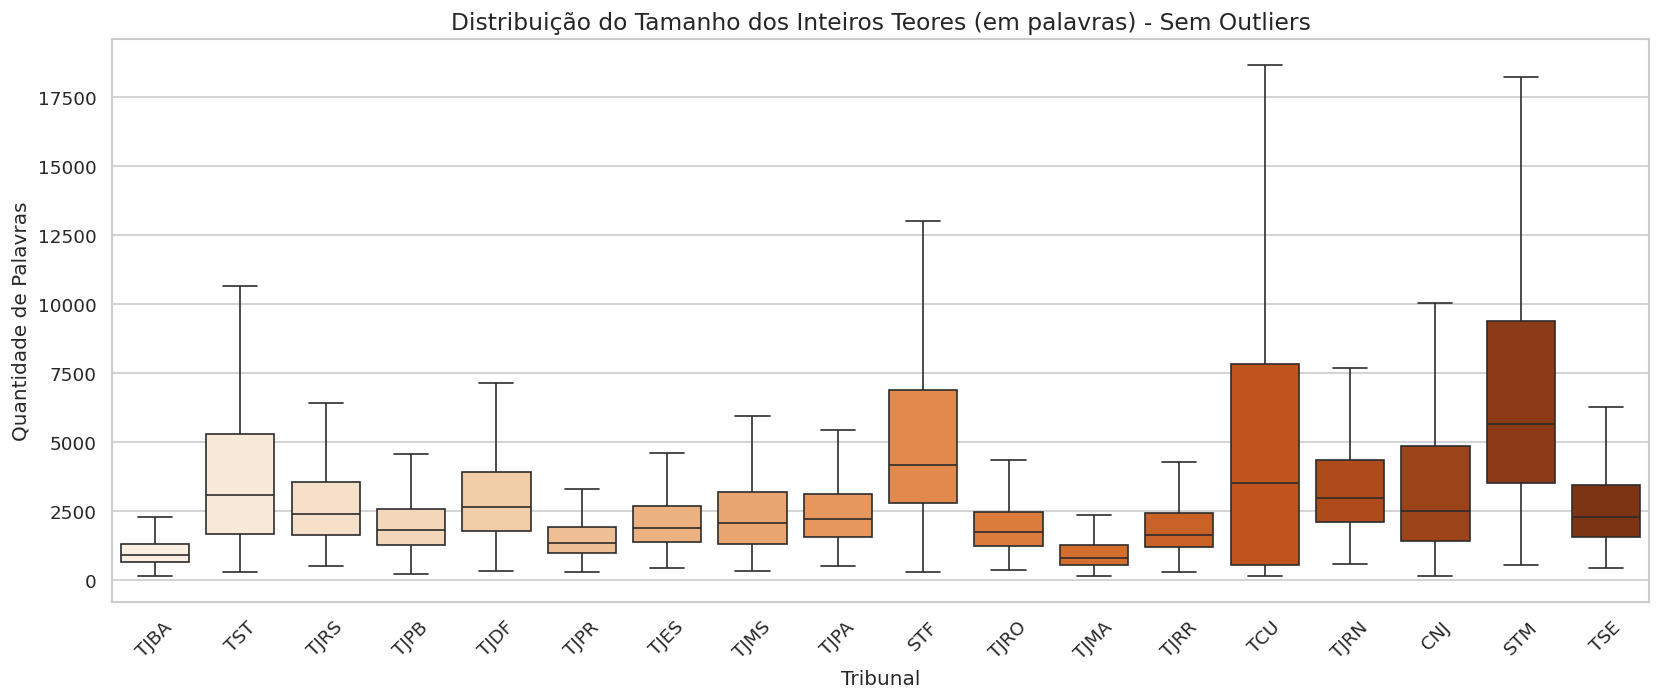

In [13]:
# Preparando os dados subamostrados para os Boxplots
dados_ementa = []
dados_teor = []

ordem_tribunais = df_resumo['Tribunal'].tolist()

for trib in ordem_tribunais:
    if trib in todas_ementas_words:
        for val in todas_ementas_words[trib]:
            dados_ementa.append({'Tribunal': trib, 'Palavras': val})
        for val in todos_teores_words[trib]:
            dados_teor.append({'Tribunal': trib, 'Palavras': val})

df_ementa_plot = pd.DataFrame(dados_ementa)
df_teor_plot = pd.DataFrame(dados_teor)

# Gráfico 2: Distribuição do tamanho das Ementas
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_ementa_plot, x='Tribunal', y='Palavras', hue='Tribunal', order=ordem_tribunais, palette='Blues', showfliers=False, legend=False)
plt.title('Distribuição do Tamanho das Ementas (em palavras) - Sem Outliers', fontsize=14)
plt.xlabel('Tribunal', fontsize=12)
plt.ylabel('Quantidade de Palavras', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico 3: Distribuição do tamanho dos Inteiros Teores
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_teor_plot, x='Tribunal', y='Palavras', hue='Tribunal', order=ordem_tribunais, palette='Oranges', showfliers=False, legend=False)
plt.title('Distribuição do Tamanho dos Inteiros Teores (em palavras) - Sem Outliers', fontsize=14)
plt.xlabel('Tribunal', fontsize=12)
plt.ylabel('Quantidade de Palavras', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Visualizador Qualitativo
Extrai uma amostra aleatória diretamente do disco para leitura completa das Ementas e Inteiros Teores em painéis HTML.

In [15]:
import random
from IPython.display import HTML, display
import json

html_content = "<h3 style='font-family: sans-serif; color: #333;'>Amostras Aleatórias (Texto Completo) por Tribunal</h3>"

# Itera sobre os tribunais disponíveis no resumo
for _, row in df_resumo.iterrows():
    tribunal = row['Tribunal']
    # Encontra o caminho do arquivo para o tribunal
    arquivo_path = df_inventario[df_inventario['Tribunal'] == tribunal]['Caminho'].values[0]

    # Pular um número aleatório de linhas (entre 0 e 500) para pegar um documento diferente a cada execução
    # Limitado para garantir que a execução seja instantânea, mesmo em arquivos enormes.
    pulos = random.randint(0, 500)

    exemplo = None
    with open(arquivo_path, 'r', encoding='utf-8', errors='replace') as f:
        for i, linha in enumerate(f):
            if i < pulos:
                continue

            linha = linha.strip()
            if not linha:
                continue

            try:
                rec = json.loads(linha)
                if rec.get('str_ementa') and rec.get('str_inteiro_teor'):
                    exemplo = rec
                    break
            except:
                continue

    if exemplo:
        # Formata quebras de linha para HTML
        ementa_html = str(exemplo.get('str_ementa', '')).replace('\n', '<br>').replace('\r', '')
        teor_html = str(exemplo.get('str_inteiro_teor', '')).replace('\n', '<br>').replace('\r', '')
        numero = exemplo.get('str_numero_unico', 'S/N')

        # Monta o HTML usando <details> e <summary> para criar um accordion nativo do HTML5
        html_content += f'''
        <details style="margin-bottom: 15px; border: 1px solid #ddd; padding: 10px; border-radius: 8px; font-family: sans-serif; background-color: #fff;">
            <summary style="font-weight: bold; cursor: pointer; font-size: 16px; color: #2c3e50;">
                {tribunal} - Processo: {numero}
            </summary>
            <div style="margin-top: 15px;">
                <h4 style="color: #2980b9; margin-bottom: 8px;">Ementa</h4>
                <div style="background-color: #f8f9fa; padding: 15px; border-left: 5px solid #3498db; max-height: 250px; overflow-y: auto; font-size: 14px; line-height: 1.6; border-radius: 0 4px 4px 0;">
                    {ementa_html}
                </div>
                <h4 style="color: #d35400; margin-top: 20px; margin-bottom: 8px;">Inteiro Teor (Completo)</h4>
                <div style="background-color: #fcf3cf; padding: 15px; border-left: 5px solid #e67e22; max-height: 500px; overflow-y: auto; font-size: 14px; line-height: 1.6; border-radius: 0 4px 4px 0;">
                    {teor_html}
                </div>
            </div>
        </details>
        '''

display(HTML(html_content))